# Классификация мусора по фото

Курсовая работа по дисциплине «Интеллектуальные методы распознавания изображения».

**Задача:** классификация фотографий отходов на 6 классов — картон, стекло, металл, бумага, пластик, прочее.

**Модель:** MobileNetV2 с предобученными весами ImageNet ([статья](https://arxiv.org/abs/1801.04381)).

**Данные:** [Garbage Classification на Kaggle](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification).

## 1. Импорты и настройки

In [1]:
import os
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASSES = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
CLASSES_RU = {
    'cardboard': 'картон',
    'glass': 'стекло',
    'metal': 'металл',
    'paper': 'бумага',
    'plastic': 'пластик',
    'trash': 'прочее',
}

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Загрузка и разведка данных

Датасет скачиваем прямо с Kaggle библиотекой `kagglehub`. В Colab она уже установлена, а публичный датасет скачивается без входа в аккаунт.

В архиве датасет лежит дважды: в папках `Garbage classification` и `garbage classification` (отличаются только регистром, файлы одинаковые). Берём только одну копию, иначе одни и те же фото попадут и в train, и в test.

In [2]:
dataset_path = kagglehub.dataset_download('asdasdasasdas/garbage-classification')

DATA_DIR = os.path.join(dataset_path, 'Garbage classification', 'Garbage classification')
print(sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'garbage-classification' dataset.
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


### Количество изображений по классам

In [3]:
counts = [len(os.listdir(os.path.join(DATA_DIR, cls))) for cls in CLASSES]

df_counts = pd.DataFrame({
    'класс': [CLASSES_RU[cls] for cls in CLASSES],
    'количество': counts,
})
df_counts['доля, %'] = (df_counts['количество'] / df_counts['количество'].sum() * 100).round(1)

print('Всего изображений:', df_counts['количество'].sum())
df_counts

Всего изображений: 2527


,класс,количество,"доля, %"
0,картон,403,15.9
1,стекло,501,19.8
2,металл,410,16.2
3,бумага,594,23.5
4,пластик,482,19.1
5,прочее,137,5.4


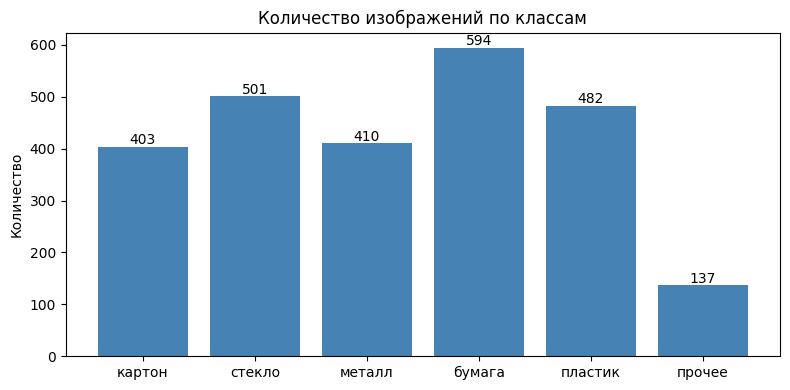

In [4]:
plt.figure(figsize=(8, 4))
plt.bar(df_counts['класс'], df_counts['количество'], color='steelblue')
for i, value in enumerate(df_counts['количество']):
    plt.text(i, value + 5, str(value), ha='center')
plt.title('Количество изображений по классам')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

### Примеры изображений

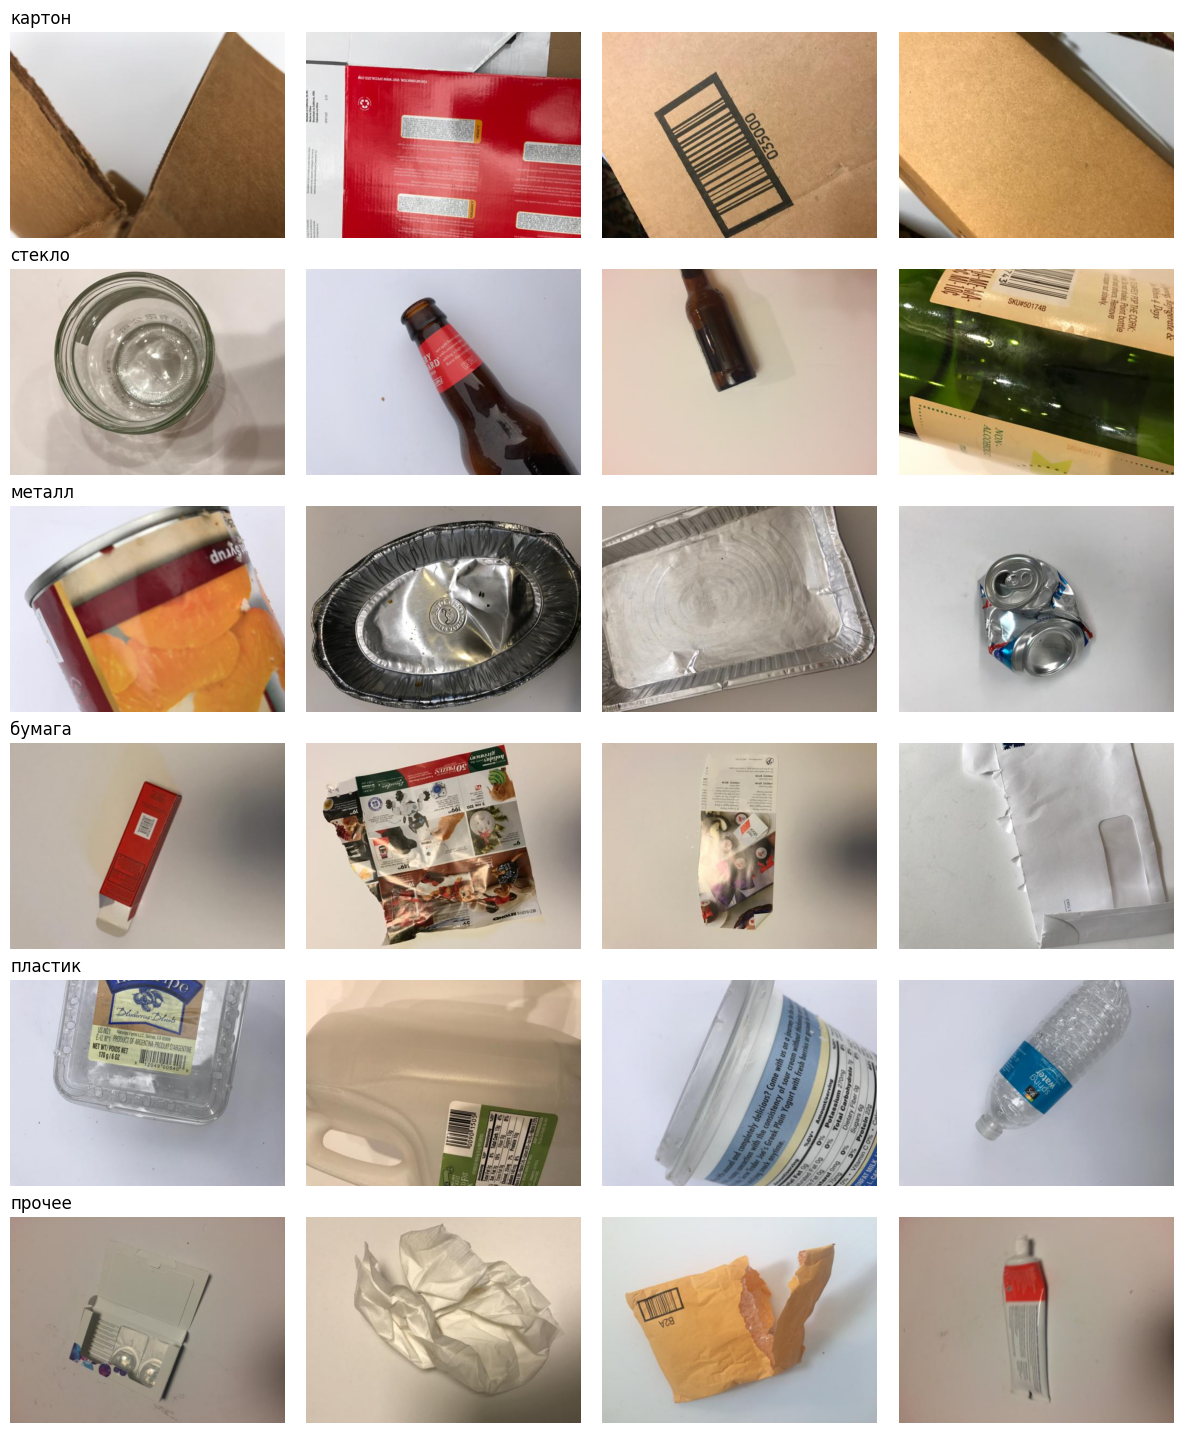

In [5]:
n_examples = 4
fig, axes = plt.subplots(len(CLASSES), n_examples, figsize=(n_examples * 3, len(CLASSES) * 2.4))

for row, cls in enumerate(CLASSES):
    files = random.sample(os.listdir(os.path.join(DATA_DIR, cls)), n_examples)
    for col, fname in enumerate(files):
        img = Image.open(os.path.join(DATA_DIR, cls, fname))
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
    axes[row, 0].set_title(CLASSES_RU[cls], loc='left')

plt.tight_layout()
plt.show()

### Размеры и цветовой режим изображений

In [6]:
rows = []
for cls in CLASSES:
    for fname in os.listdir(os.path.join(DATA_DIR, cls)):
        with Image.open(os.path.join(DATA_DIR, cls, fname)) as img:
            rows.append({'ширина': img.width, 'высота': img.height, 'режим': img.mode})

pd.DataFrame(rows).value_counts()

,,,count
ширина,высота,режим,
512,384,RGB,2527


### Выводы по данным

- В датасете 2527 изображений, 6 классов.
- Классы несбалансированы: больше всего бумаги (594, 23.5%), меньше всего класса «прочее» (137, 5.4%). Это нужно учесть: делить данные со стратификацией и смотреть не только на accuracy, но и на метрики по классам.
- Все изображения одного размера 512×384 в RGB. В кадре один объект, в основном на однотонном светлом фоне, часть фото сделана крупным планом.
- Некоторые классы визуально похожи: например, прозрачные бутылки из стекла и пластика. Скорее всего, модель будет их путать.
- Данных мало (около 400 фото на класс), поэтому обучать большую сеть с нуля будет тяжело. Это аргумент в пользу transfer learning с предобученной на ImageNet моделью.

## 3. Препроцессинг и разделение на train/val/test

Делим данные на три части в пропорции 70/15/15:
- **train** — на ней обучаем модель;
- **val** — по ней следим за обучением и выбираем лучшую эпоху;
- **test** — откладываем до самого конца и используем только для итоговой оценки.

Разбиение делаем **со стратификацией**: доля каждого класса во всех трёх частях остаётся такой же, как во всём датасете. Без этого в маленький test могло бы попасть слишком мало фото класса «прочее».

In [7]:
filepaths = []
labels = []
for label, cls in enumerate(CLASSES):
    for fname in sorted(os.listdir(os.path.join(DATA_DIR, cls))):
        filepaths.append(os.path.join(DATA_DIR, cls, fname))
        labels.append(label)

filepaths = np.array(filepaths)
labels = np.array(labels)

# сначала отделяем 30% под val+test, потом делим их пополам
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    filepaths, labels, test_size=0.3, stratify=labels, random_state=SEED)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=SEED)

print('train:', len(train_paths), ' val:', len(val_paths), ' test:', len(test_paths))

train: 1768  val: 379  test: 380


In [8]:
df_split = pd.DataFrame({
    'train': np.bincount(train_labels),
    'val': np.bincount(val_labels),
    'test': np.bincount(test_labels),
}, index=[CLASSES_RU[cls] for cls in CLASSES])
df_split.loc['всего'] = df_split.sum()
df_split

,train,val,test
картон,282,61,60
стекло,350,75,76
металл,287,61,62
бумага,416,89,89
пластик,337,72,73
прочее,96,21,20
всего,1768,379,380


### Загрузка изображений через tf.data

Все картинки приводим к размеру **224×224** — это стандартный размер входа MobileNetV2. Исходные фото 4:3, так что пропорции немного искажаются, но для классификации это не критично.

Пиксели оставляем в диапазоне 0–255. Нормализацию каждая модель делает сама в первом слое: простая CNN делит на 255, а MobileNetV2 использует свою функцию `preprocess_input`.

`cache()` сохраняет уже декодированные картинки в памяти, чтобы не читать JPEG с диска на каждой эпохе, а `prefetch()` готовит следующий батч, пока GPU считает текущий.

In [9]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label


def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(train_paths, train_labels, shuffle=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

images, batch_labels = next(iter(train_ds))
print('Батч:', images.shape, images.dtype)
print('Диапазон пикселей:', float(tf.reduce_min(images)), '-', float(tf.reduce_max(images)))

Батч: (32, 224, 224, 3) <dtype: 'float32'>
Диапазон пикселей: 0.0 - 255.0


### Аугментация

Данных мало, поэтому на обучении будем случайно менять картинки: отражать, поворачивать, приближать или отдалять, менять контраст. Так модель каждый раз видит немного другое изображение и меньше переобучается.

Отражаем и по горизонтали, и по вертикали: многие объекты сняты сверху, и у них нет «верха» и «низа».

Аугментация сделана слоями Keras. Мы добавим её внутрь моделей: такие слои работают только во время обучения, а на val и test автоматически отключаются.

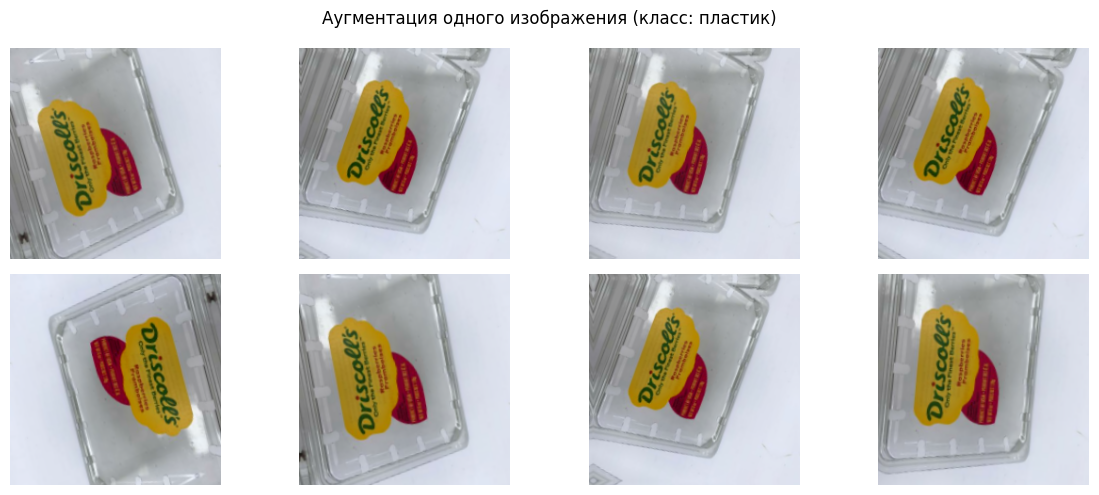

In [10]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name='augmentation')

img = images[0]
plt.figure(figsize=(12, 5))
for i in range(8):
    augmented = data_augmentation(img[tf.newaxis], training=True)[0]
    plt.subplot(2, 4, i + 1)
    plt.imshow(np.clip(augmented.numpy(), 0, 255).astype('uint8'))
    plt.axis('off')
plt.suptitle('Аугментация одного изображения (класс: ' + CLASSES_RU[CLASSES[int(batch_labels[0])]] + ')')
plt.tight_layout()
plt.show()

### Веса классов

Чтобы модель не игнорировала редкий класс «прочее», при обучении будем передавать веса классов: ошибка на редком классе штрафуется сильнее. Веса считаются по train как `всего / (число_классов × размер_класса)`.

In [11]:
weights = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=train_labels)
class_weight = dict(enumerate(weights))

pd.Series(weights.round(2), index=[CLASSES_RU[cls] for cls in CLASSES], name='вес класса')

,вес класса
картон,1.04
стекло,0.84
металл,1.03
бумага,0.71
пластик,0.87
прочее,3.07


## 4. Бейзлайн: простая CNN

Сначала обучим небольшую свёрточную сеть с нуля, без предобученных весов. Это точка отсчёта: потом сравним с ней MobileNetV2 и увидим, сколько даёт transfer learning.

Архитектура:
- аугментация (работает только при обучении) и нормализация пикселей в диапазон 0–1;
- 4 свёрточных блока, число фильтров 32 → 64 → 128 → 128. Каждый блок: свёртка 3×3 → BatchNormalization → ReLU → MaxPooling. MaxPooling уменьшает картинку в 2 раза: 224 → 112 → 56 → 28 → 14;
- BatchNormalization нормирует выход свёртки по батчу (среднее 0, разброс 1). Так распределение входов следующего слоя меньше «плавает» во время обучения, и сеть учится быстрее и стабильнее;
- GlobalAveragePooling вместо Flatten: усредняет каждую карту признаков в одно число. Получается 128 признаков вместо 14·14·128 = 25088, параметров намного меньше, и сеть слабее переобучается;
- Dropout 0.3 и выходной слой на 6 классов с softmax.

In [12]:
def conv_block(filters):
    return [
        tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.ReLU(),
        tf.keras.layers.MaxPooling2D(),
    ]


baseline_model = tf.keras.Sequential([
    tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,
    tf.keras.layers.Rescaling(1. / 255),

    *conv_block(32),
    *conv_block(64),
    *conv_block(128),
    *conv_block(128),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(CLASSES), activation='softmax'),
], name='baseline_cnn')

baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,662 (947.90 KB)

 Trainable params: 241,958 (945.15 KB)

 Non-trainable params: 704 (2.75 KB)

### Обучение

- Оптимизатор Adam с learning rate 0.001.
- Функция потерь `sparse_categorical_crossentropy`: метки у нас числами 0–5, а не one-hot векторами.
- Передаём веса классов, посчитанные выше.
- `ReduceLROnPlateau` уменьшает learning rate в 2 раза, если loss на валидации не улучшается 3 эпохи. Большой шаг полезен в начале, а ближе к концу маленький шаг помогает аккуратно дойти до минимума.
- `EarlyStopping` останавливает обучение, если loss на валидации не улучшается 8 эпох подряд, и возвращает веса с лучшей эпохи.

In [13]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
]

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 171ms/step - accuracy: 0.4157 - loss: 1.4934 - val_accuracy: 0.0660 - val_loss: 1.9631 - learning_rate: 0.0010
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.5085 - loss: 1.2973 - val_accuracy: 0.1029 - val_loss: 2.1154 - learning_rate: 0.0010
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 130ms/step - accuracy: 0.5096 - loss: 1.2497 - val_accuracy: 0.2216 - val_loss: 2.1785 - learning_rate: 0.0010
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 130ms/step - accuracy: 0.5407 - loss: 1.2000 - val_accuracy: 0.2111 - val_loss: 1.8827 - learning_rate: 0.0010
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 134ms/step - accuracy: 0.5577 - loss: 1.1608 - val_accuracy: 0.2137 - val_loss: 2.1763 - learning_rate: 0.0010
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 135ms/step - accuracy: 0.5617 - loss: 1.1152 - val_accuracy: 0.1953 - val_loss: 2.1913 - learning_rate: 0.0010
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 134ms/step - accuracy: 0.5730 - loss: 1.1073 -

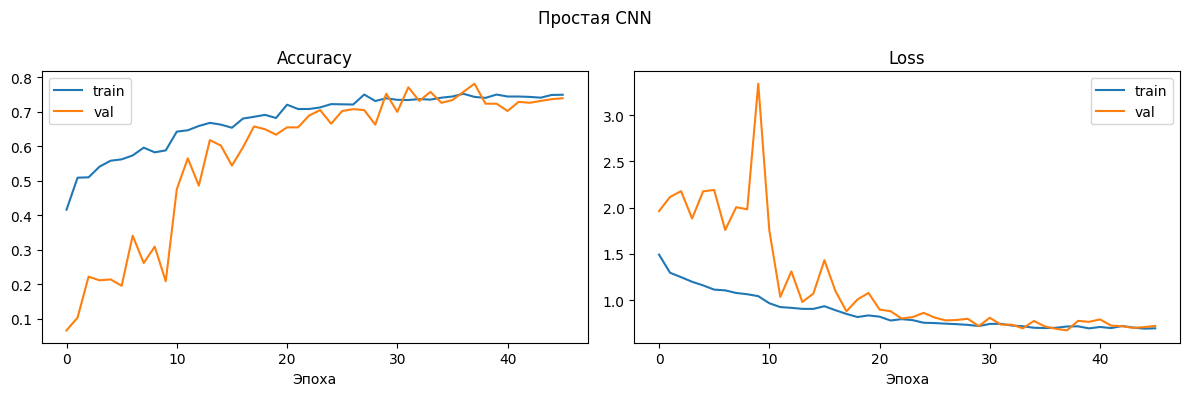

In [14]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history['accuracy'], label='train')
    axes[0].plot(history.history['val_accuracy'], label='val')
    axes[0].set_title('Accuracy')
    axes[0].set_xlabel('Эпоха')
    axes[0].legend()

    axes[1].plot(history.history['loss'], label='train')
    axes[1].plot(history.history['val_loss'], label='val')
    axes[1].set_title('Loss')
    axes[1].set_xlabel('Эпоха')
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(baseline_history, 'Простая CNN')

In [15]:
val_loss, val_acc = baseline_model.evaluate(val_ds, verbose=0)
print(f'Простая CNN, точность на валидации: {val_acc:.3f}')

Простая CNN, точность на валидации: 0.781


### Выводы по бейзлайну

- Первая версия этой сети без BatchNormalization и без ReduceLROnPlateau давала на валидации около **0.62**. После добавления BatchNormalization в каждый свёрточный блок и снижения learning rate на плато точность выросла до **0.78**.
- Обучение остановилось на 46-й эпохе по early stopping, а веса вернулись к 38-й эпохе, где loss на валидации был минимальным. Одна эпоха занимает около 7 секунд на T4.
- Первые ~10 эпох accuracy на валидации сильно скачет (от 0.07 до 0.47), хотя на train она спокойно растёт. На валидации BatchNormalization использует накопленные (скользящие) средние по батчам, а в начале обучения веса быстро меняются и эти средние за ними не успевают. После снижения learning rate обучение успокаивается, и примерно с 20-й эпохи валидация идёт вслед за train.
- В конце обучения точность на train и val почти одинаковая (около 0.74–0.75), то есть сеть не переобучилась, а упёрлась в свой потолок. 1768 фото мало, чтобы с нуля выучить хорошие признаки (края, текстуры, формы объектов).
- Отсюда идея следующего шага: взять сеть, которая уже умеет извлекать признаки, потому что обучена на миллионе картинок ImageNet, и дообучить её под наши 6 классов.

## 5. MobileNetV2 с transfer learning

**MobileNetV2** ([Sandler et al., 2018](https://arxiv.org/abs/1801.04381)) — свёрточная сеть, спроектированная для мобильных устройств: она лёгкая и быстрая, но при этом точная. По данным статьи, на ImageNet она даёт 72% top-1 при 3.4 млн параметров. Основные идеи:
- **depthwise separable свёртки**: обычная свёртка раскладывается на две — сначала каждый канал фильтруется отдельно (depthwise), потом каналы смешиваются свёрткой 1×1 (pointwise). Вычислений получается в 8–9 раз меньше, чем у обычной свёртки 3×3;
- **inverted residual блоки**: узкий вход расширяется свёрткой 1×1, обрабатывается depthwise свёрткой и снова сжимается. Skip-соединение идёт между узкими частями, а не широкими, как в ResNet;
- **linear bottleneck**: после последнего сжатия нет ReLU, чтобы не терять информацию в узком представлении.

**Transfer learning.** Сеть уже обучена на 1.2 млн картинок ImageNet (1000 классов) и умеет извлекать общие признаки: края, текстуры, формы, части объектов. Мы берём её без последнего классификационного слоя (`include_top=False`), **замораживаем** все её веса и обучаем только новую «голову» под 6 наших классов. На шаге 6 разморозим верхние слои базы и дообучим их (fine-tuning).

Входные пиксели переводим в диапазон [-1, 1], так как на ImageNet MobileNetV2 обучалась именно с такой нормализацией.

In [16]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet',
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
# то же, что mobilenet_v2.preprocess_input: пиксели из [0, 255] в [-1, 1]
x = tf.keras.layers.Rescaling(1. / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation='softmax')(x)

mobilenet_model = tf.keras.Model(inputs, outputs, name='mobilenet_v2_transfer')
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenet_v2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Обучение головы

Обучаются только веса последнего Dense-слоя (1280 признаков × 6 классов + 6 смещений = 7 686 параметров), а 2.2 млн весов базы заморожены. Поэтому эпоха идёт быстро, а сеть почти не может переобучиться на наших 1768 фото.

`base_model(x, training=False)` запускает базу в режиме инференса: её слои BatchNormalization используют статистики, накопленные на ImageNet, и не пересчитывают их по нашим батчам. Это важно на шаге 6, когда базу разморозим: иначе маленькие батчи испортили бы эти статистики.

In [17]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
]

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 14s 132ms/step - accuracy: 0.4706 - loss: 1.4339 - val_accuracy: 0.7124 - val_loss: 0.8127 - learning_rate: 0.0010
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.6821 - loss: 0.8839 - val_accuracy: 0.7652 - val_loss: 0.6852 - learning_rate: 0.0010
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.7477 - loss: 0.7082 - val_accuracy: 0.7863 - val_loss: 0.6379 - learning_rate: 0.0010
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.7636 - loss: 0.6506 - val_accuracy: 0.8179 - val_loss: 0.5571 - learning_rate: 0.0010
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.7868 - loss: 0.6057 - val_accuracy: 0.8179 - val_loss: 0.5463 - learning_rate: 0.0010
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.7936 - loss: 0.5713 - val_accuracy: 0.8232 - val_loss: 0.5232 - learning_rate: 0.0010
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.8032 - loss: 0.5456 - val_a

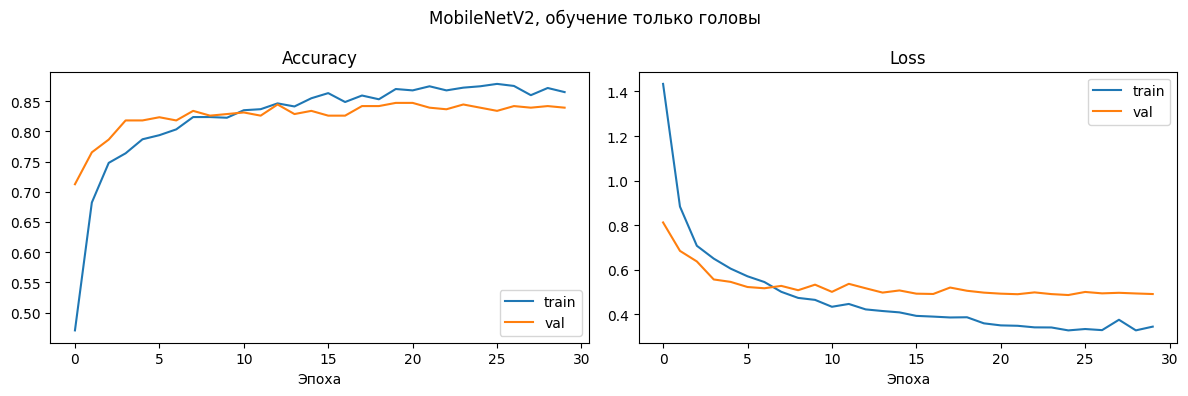

MobileNetV2 (замороженная база), точность на валидации: 0.839


In [18]:
plot_history(mobilenet_history, 'MobileNetV2, обучение только головы')

val_loss, val_acc = mobilenet_model.evaluate(val_ds, verbose=0)
print(f'MobileNetV2 (замороженная база), точность на валидации: {val_acc:.3f}')

### Выводы по MobileNetV2 с замороженной базой

- Точность на валидации **0.839**, хотя обучались всего 7 686 параметров из 2.27 млн. Это заметно лучше простой CNN с нуля (0.78), которая обучала все свои 242 тыс. весов.
- Модель учится очень быстро: уже на 4-й эпохе точность на валидации 0.82 (у простой CNN на 4-й эпохе было 0.21). Признаки ImageNet (края, текстуры, формы) хорошо подходят и для фото мусора.
- Примерно с 8-й эпохи валидация выходит на плато 0.83–0.85, а train продолжает расти до 0.86–0.88. Голова уже взяла от замороженных признаков почти всё, что могла.
- Признаки ImageNet общие и не заточены под нашу задачу. Например, чтобы отличать прозрачное стекло от прозрачного пластика, нужны более специфичные признаки. Поэтому следующий шаг — fine-tuning: разморозить верхние слои базы и аккуратно дообучить их на наших данных.

## 6. Fine-tuning

Теперь размораживаем **верхние слои** базы и дообучаем их вместе с головой.

- Нижние слои сети выделяют простые признаки (края, цветовые пятна), они универсальны и подходят для любых фото, поэтому их оставляем замороженными.
- Верхние слои собирают из простых признаков более сложные, которые заточены под классы ImageNet. Их и подстраиваем под наши 6 классов.
- В MobileNetV2 около 150 слоёв. Размораживаем всё, начиная со 100-го.
- Learning rate берём в 100 раз меньше, чем при обучении головы (1e-5). Иначе большие шаги градиента быстро разрушат предобученные веса, и сеть «забудет» то, чему научилась на ImageNet.

Fine-tuning делаем **после** обучения головы, а не сразу. Пока голова случайная, через неё в базу шли бы большие и бессмысленные градиенты.

**Слои BatchNormalization оставляем замороженными**, даже в размороженной части базы. В Keras замороженный BatchNormalization всегда работает в режиме инференса и использует статистики, посчитанные на ImageNet. Если же дать ему обучаться, он начнёт пересчитывать среднее и разброс по нашим батчам из 32 картинок. Признаки, на которых обучилась голова, сразу «поплывут», и точность упадёт. Именно это произошло в первой попытке fine-tuning без этой заморозки: точность на валидации стала ниже, чем до fine-tuning.

In [19]:
FINE_TUNE_AT = 100

base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False
for layer in base_model.layers[FINE_TUNE_AT:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(layer.trainable for layer in base_model.layers)
print('Слоёв в базе:', len(base_model.layers), ' из них обучаются:', n_trainable)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
mobilenet_model.summary()

Слоёв в базе: 154  из них обучаются: 36


Model: "mobilenet_v2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 1,847,302 (7.05 MB)

 Non-trainable params: 418,368 (1.60 MB)

После изменения `trainable` модель нужно заново скомпилировать (`compile`), иначе изменения не вступят в силу.

In [20]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
]

finetune_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 14s 120ms/step - accuracy: 0.8614 - loss: 0.3615 - val_accuracy: 0.8602 - val_loss: 0.4757 - learning_rate: 1.0000e-05
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.8801 - loss: 0.3155 - val_accuracy: 0.8470 - val_loss: 0.4579 - learning_rate: 1.0000e-05
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.8880 - loss: 0.2997 - val_accuracy: 0.8496 - val_loss: 0.4521 - learning_rate: 1.0000e-05
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.8937 - loss: 0.2862 - val_accuracy: 0.8681 - val_loss: 0.4308 - learning_rate: 1.0000e-05
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.8976 - loss: 0.2806 - val_accuracy: 0.8522 - val_loss: 0.4667 - learning_rate: 1.0000e-05
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.9067 - loss: 0.2528 - val_accuracy: 0.8681 - val_loss: 0.4227 - learning_rate: 1.0000e-05
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.918

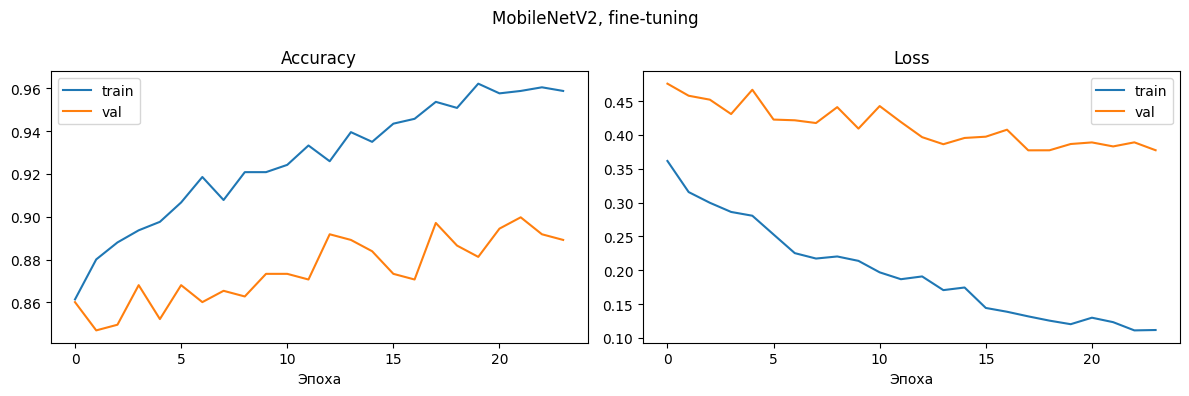

MobileNetV2 после fine-tuning, точность на валидации: 0.897


In [21]:
plot_history(finetune_history, 'MobileNetV2, fine-tuning')

val_loss, val_acc = mobilenet_model.evaluate(val_ds, verbose=0)
print(f'MobileNetV2 после fine-tuning, точность на валидации: {val_acc:.3f}')

### Обучение целиком: голова + fine-tuning

Склеиваем две истории обучения в один график. Пунктирная линия — момент, когда разморозили верхние слои базы.

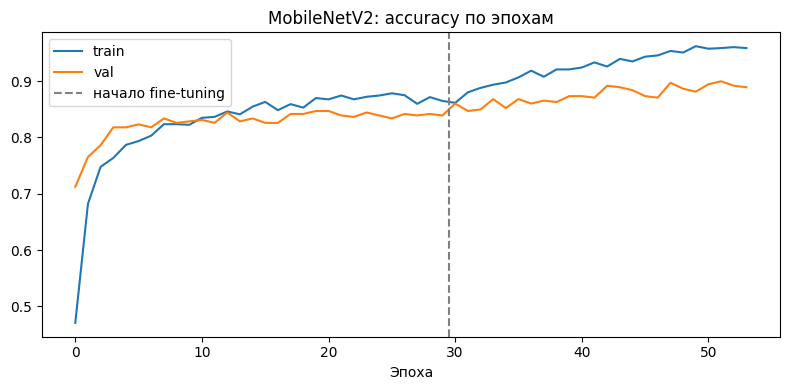

In [22]:
acc = mobilenet_history.history['accuracy'] + finetune_history.history['accuracy']
val_acc_all = mobilenet_history.history['val_accuracy'] + finetune_history.history['val_accuracy']
start_ft = len(mobilenet_history.history['accuracy'])

plt.figure(figsize=(8, 4))
plt.plot(acc, label='train')
plt.plot(val_acc_all, label='val')
plt.axvline(start_ft - 0.5, color='gray', linestyle='--', label='начало fine-tuning')
plt.title('MobileNetV2: accuracy по эпохам')
plt.xlabel('Эпоха')
plt.legend()
plt.tight_layout()
plt.show()

### Выводы по fine-tuning

- Fine-tuning поднял точность на валидации с **0.839** (обучение только головы) до **0.897**, то есть примерно на 6 процентных пунктов.
- Дообучались 36 из 154 слоёв базы: все слои начиная со 100-го, кроме BatchNormalization. Это 1.85 млн обучаемых параметров.
- На общем графике видно: после начала fine-tuning (пунктир) растут и train, и val. Точность на валидации поднялась с 0.86 на первой эпохе fine-tuning до 0.90 к 18-й, loss на валидации снизился с 0.48 до 0.38.
- Обучение остановилось по early stopping на 24-й эпохе, а веса вернулись к 18-й, где loss на валидации был минимальным.
- Train дошёл до ~0.96, а val до ~0.89–0.90. Разрыв в 6–7 пунктов означает, что модель начинает немного переобучаться на 1768 фото.
- Первая попытка fine-tuning была **без заморозки BatchNormalization**. Уже на первой эпохе точность на train упала примерно с 0.86 до 0.72, а на валидации стала 0.815 вместо 0.834 до fine-tuning. Это хорошо показывает, почему при fine-tuning слои BatchNormalization надо держать замороженными.
- Итоговую модель (MobileNetV2 после fine-tuning) дальше оцениваем на отложенной тестовой выборке.

## 7. Оценка результатов

Теперь впервые используем **тестовую выборку** (380 фото). Ни при обучении, ни при выборе параметров она не участвовала, поэтому оценка на ней честная: она показывает, как модель будет работать на новых фото.

Метрики:
- **accuracy** — доля правильных ответов;
- **precision** класса — из всех фото, которые модель назвала этим классом, какая доля действительно этого класса;
- **recall** класса — из всех фото этого класса, какую долю модель нашла;
- **F1** — среднее гармоническое precision и recall;
- **macro F1** — среднее F1 по всем классам без учёта их размера. Редкий класс «прочее» весит в ней столько же, сколько бумага, поэтому при несбалансированных классах она честнее, чем accuracy.

In [23]:
class_names_ru = [CLASSES_RU[cls] for cls in CLASSES]

baseline_probs = baseline_model.predict(test_ds, verbose=0)
mobilenet_probs = mobilenet_model.predict(test_ds, verbose=0)
baseline_pred = baseline_probs.argmax(axis=1)
mobilenet_pred = mobilenet_probs.argmax(axis=1)

df_results = pd.DataFrame({
    'accuracy': [accuracy_score(test_labels, baseline_pred),
                 accuracy_score(test_labels, mobilenet_pred)],
    'macro F1': [f1_score(test_labels, baseline_pred, average='macro'),
                 f1_score(test_labels, mobilenet_pred, average='macro')],
}, index=['Простая CNN', 'MobileNetV2 + fine-tuning']).round(3)
df_results

,accuracy,macro F1
Простая CNN,0.711,0.696
MobileNetV2 + fine-tuning,0.871,0.854


### Метрики по классам (MobileNetV2)

In [24]:
print(classification_report(test_labels, mobilenet_pred, target_names=class_names_ru, digits=3))

              precision    recall  f1-score   support

      картон      0.897     0.867     0.881        60
      стекло      0.890     0.855     0.872        76
      металл      0.843     0.952     0.894        62
      бумага      0.872     0.921     0.896        89
     пластик      0.906     0.795     0.847        73
      прочее      0.714     0.750     0.732        20

    accuracy                          0.871       380
   macro avg      0.854     0.857     0.854       380
weighted avg      0.873     0.871     0.871       380



### Матрица ошибок

Строки — истинный класс, столбцы — предсказанный. На диагонали правильные ответы, вне диагонали ошибки. Справа та же матрица, но в долях от истинного класса: на диагонали получается recall каждого класса.

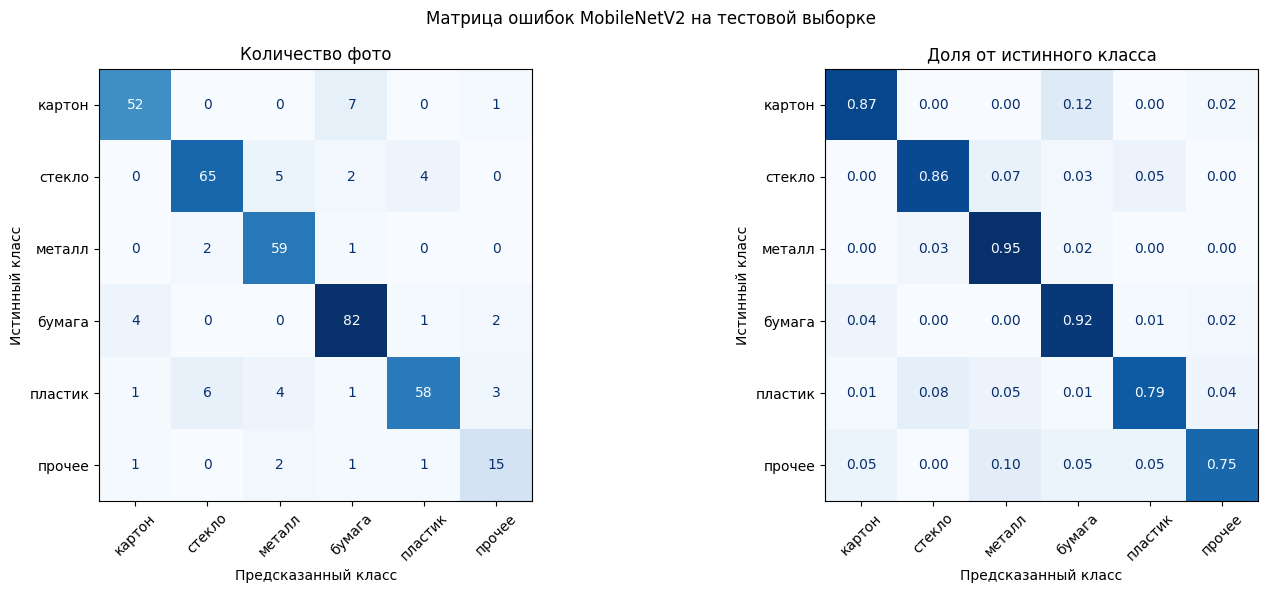

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    test_labels, mobilenet_pred, display_labels=class_names_ru,
    cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Количество фото')

ConfusionMatrixDisplay.from_predictions(
    test_labels, mobilenet_pred, display_labels=class_names_ru,
    normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=axes[1])
axes[1].set_title('Доля от истинного класса')

for ax in axes:
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.tick_params(axis='x', rotation=45)

fig.suptitle('Матрица ошибок MobileNetV2 на тестовой выборке')
plt.tight_layout()
plt.show()

In [26]:
cm = confusion_matrix(test_labels, mobilenet_pred)
np.fill_diagonal(cm, 0)

pairs = []
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] > 0:
            pairs.append((cm[i, j], class_names_ru[i], class_names_ru[j]))

print('Самые частые ошибки (истинный класс -> предсказанный):')
for count, true_cls, pred_cls in sorted(pairs, reverse=True)[:5]:
    print(f'  {true_cls} -> {pred_cls}: {count}')

Самые частые ошибки (истинный класс -> предсказанный):
  картон -> бумага: 7
  пластик -> стекло: 6
  стекло -> металл: 5
  стекло -> пластик: 4
  пластик -> металл: 4


### Примеры ошибок

Посмотрим на фото, на которых модель ошиблась. Над каждым — истинный класс, ответ модели и её уверенность (вероятность выбранного класса).

Ошибок на test: 49 из 380


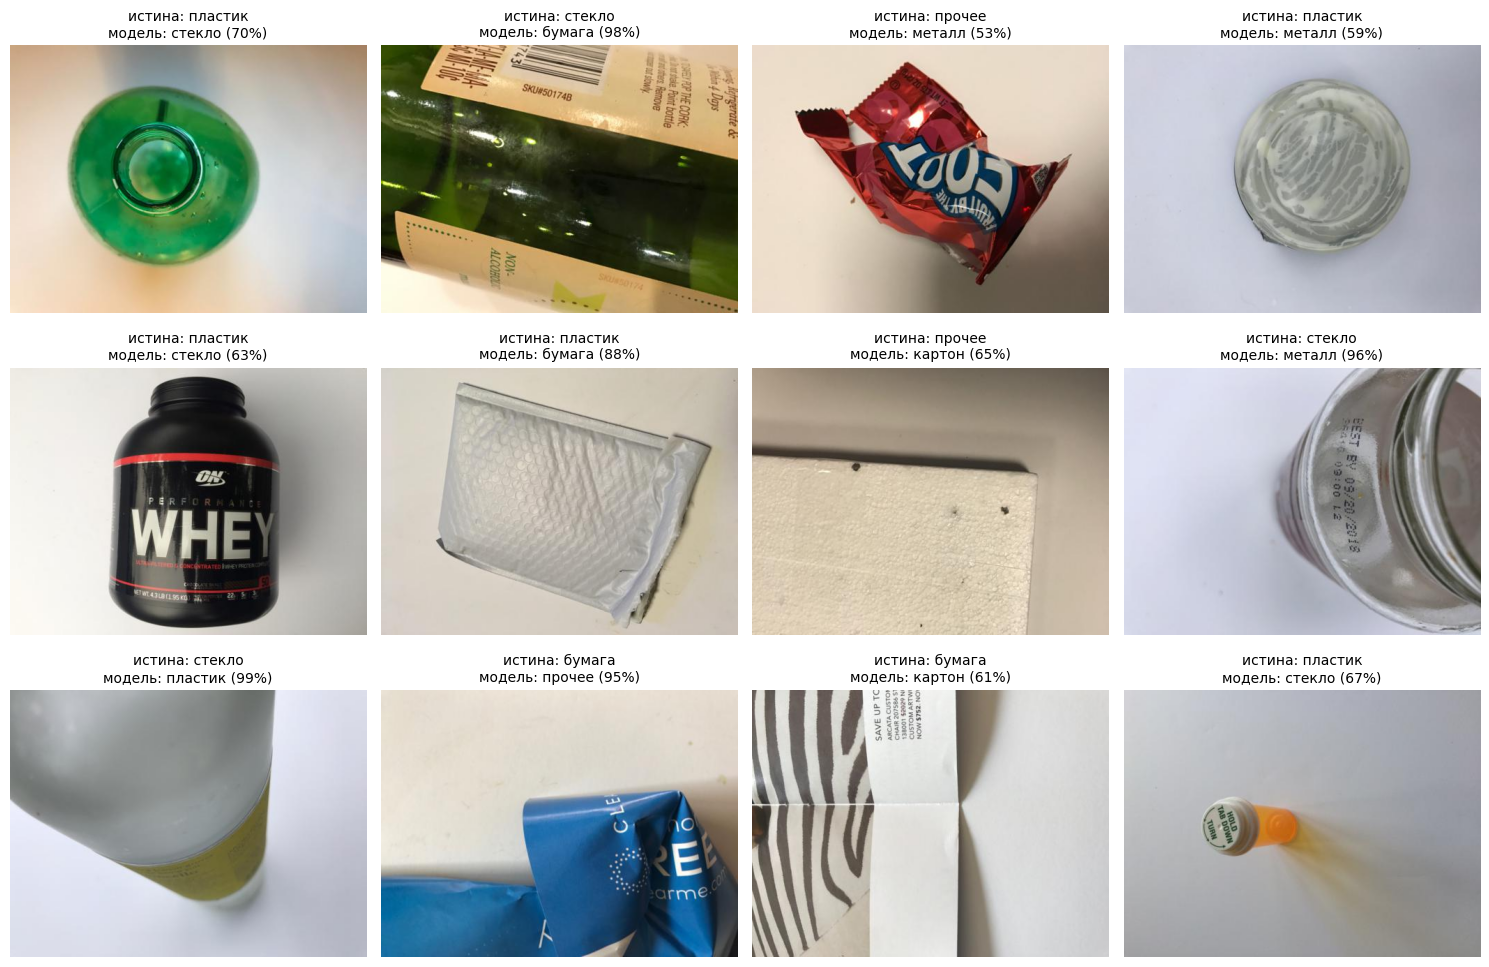

In [27]:
wrong = np.where(mobilenet_pred != test_labels)[0]
print('Ошибок на test:', len(wrong), 'из', len(test_labels))

n_show = min(12, len(wrong))
plt.figure(figsize=(15, 10))
for k, i in enumerate(wrong[:n_show]):
    true_cls = CLASSES_RU[CLASSES[test_labels[i]]]
    pred_cls = CLASSES_RU[CLASSES[mobilenet_pred[i]]]
    confidence = mobilenet_probs[i].max()

    plt.subplot(3, 4, k + 1)
    plt.imshow(Image.open(test_paths[i]))
    plt.title(f'истина: {true_cls}\nмодель: {pred_cls} ({confidence:.0%})', fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

### Выводы по оценке на тестовой выборке

- На тесте MobileNetV2 после fine-tuning даёт **accuracy 0.871** и **macro F1 0.854**, простая CNN с нуля — 0.711 и 0.696. Transfer learning улучшил accuracy на 16 процентных пунктов.
- На тесте точность немного ниже, чем на валидации (0.897). Это ожидаемо: по валидации мы выбирали лучшую эпоху и снижали learning rate, поэтому оценка на ней немного оптимистичная. Тест в этом не участвовал, и его цифры честные.
- Лучше всего модель распознаёт **металл** (recall 0.95, F1 0.89) и **бумагу** (recall 0.92, F1 0.90). Хуже всего — **пластик** (recall 0.79) и **прочее** (F1 0.73). В тесте всего 20 фото класса «прочее», поэтому каждая ошибка на нём меняет recall сразу на 5 пунктов.
- Несмотря на то что «прочее» — всего 5% датасета, recall у него 0.75. Здесь помогли веса классов при обучении.
- Всего на тесте 49 ошибок из 380. Самые частые путаницы: картон → бумага (7), **стекло ↔ пластик** (6 + 4 = 10, около пятой части всех ошибок) и стекло/пластик → металл (5 + 4 = 9).
- По примерам ошибок видно, в чём сложность:
  - цветные пластиковые бутылки (зелёная, оранжевая) модель принимает за стекло, а гладкую стеклянную бутылку крупным планом — за пластик;
  - стеклянная бутылка с большой бумажной этикеткой распознана как бумага, а стеклянная банка с бликами — как металл;
  - блестящую обёртку из фольги (класс «прочее») модель принимает за металл, а пенопласт — за картон;
  - некоторые фото сняты так близко, что виден только кусок объекта, и их сложно классифицировать даже человеку.
- Часть ошибок модель делает с высокой уверенностью (95–99%), то есть вероятности модели не всегда можно считать надёжной оценкой её правоты.

## 8. Демо

[Gradio](https://www.gradio.app/) — библиотека, которая в несколько строк делает веб-интерфейс для модели. Интерфейс открывается прямо в Colab: загружаешь фото, и модель показывает три самых вероятных класса.

Функция `predict` делает с фото то же, что и наш конвейер данных: переводит в RGB и уменьшает до 224×224. Нормализация и остальное уже встроены в модель.

Gradio в Colab по умолчанию не установлен, поэтому ставим его прямо здесь.

In [28]:
!pip install -q gradio
import gradio as gr

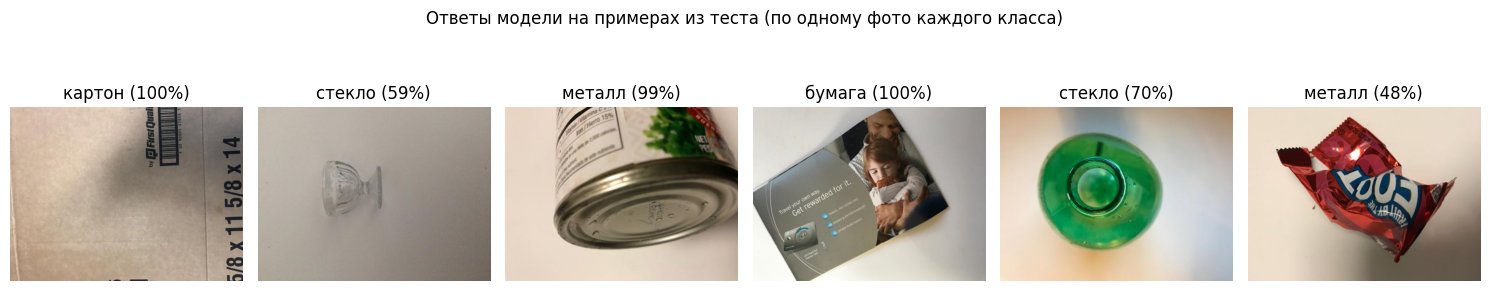

In [29]:
def predict(image):
    image = np.array(image.convert('RGB'))
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    probs = mobilenet_model.predict(image[tf.newaxis], verbose=0)[0]
    return {CLASSES_RU[cls]: float(p) for cls, p in zip(CLASSES, probs)}


# по одному тестовому фото каждого класса; копируем в рабочую папку,
# потому что gradio показывает примеры только оттуда
os.makedirs('examples', exist_ok=True)
example_files = []
for label, cls in enumerate(CLASSES):
    src = test_paths[np.where(test_labels == label)[0][0]]
    dst = os.path.join('examples', cls + '.jpg')
    shutil.copy(src, dst)
    example_files.append(dst)

plt.figure(figsize=(15, 3.5))
for k, file in enumerate(example_files):
    probs = predict(Image.open(file))
    best = max(probs, key=probs.get)
    plt.subplot(1, len(example_files), k + 1)
    plt.imshow(Image.open(file))
    plt.title(f'{best} ({probs[best]:.0%})')
    plt.axis('off')
plt.suptitle('Ответы модели на примерах из теста (по одному фото каждого класса)')
plt.tight_layout()
plt.show()

In [30]:
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type='pil', label='Фото отхода'),
    outputs=gr.Label(num_top_classes=3, label='Ответ модели'),
    examples=example_files,
    title='Классификация мусора по фото',
    description='Загрузите фото — модель MobileNetV2 определит, к какому из 6 классов относится отход.',
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://44b8862d8641e899c0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Выводы по демо

- Демо работает прямо в Colab, а Gradio дополнительно даёт временную публичную ссылку, по которой интерфейс можно открыть с любого устройства.
- На шести примерах (по одному тестовому фото каждого класса) модель права в четырёх случаях: картон, стекло, металл и бумага. Зелёную пластиковую бутылку она приняла за стекло (70%), а обёртку из фольги («прочее») — за металл (48%). Это те же типичные ошибки, что и на тестовой выборке.
- На правильных ответах уверенность обычно 99–100%, а на ошибках заметно ниже (48–70%). Исключение — стеклянная рюмка: ответ правильный, но уверенность всего 59%.

## 9. Выводы

В работе решалась задача классификации фотографий отходов на 6 классов (картон, стекло, металл, бумага, пластик, прочее) на датасете из 2527 фото. Данные разделены на train/val/test (70/15/15) со стратификацией, для борьбы с дисбалансом классов использовались веса классов, для борьбы с переобучением — аугментация.

| Модель | Обучаемых параметров | Accuracy (val) | Accuracy (test) | Macro F1 (test) |
|---|---|---|---|---|
| Простая CNN с нуля | 242 тыс. | 0.781 | 0.711 | 0.696 |
| MobileNetV2, обучение только головы | 7.7 тыс. | 0.839 | — | — |
| MobileNetV2 + fine-tuning | 1.85 млн | 0.897 | **0.871** | **0.854** |

Основные выводы:
- **Transfer learning** с MobileNetV2, предобученной на ImageNet, даёт на тесте точность 0.871 против 0.711 у CNN с нуля. На маленьком датасете готовые признаки ImageNet работают намного лучше, чем признаки, выученные с нуля.
- Даже без дообучения базы (только новая голова, 7.7 тыс. параметров) MobileNetV2 обходит CNN с нуля. **Fine-tuning** верхних слоёв добавляет ещё около 6 пунктов на валидации.
- При fine-tuning важно держать слои **BatchNormalization** замороженными, иначе точность падает.
- Главная сложность задачи — визуально похожие классы: **стекло и пластик** (прозрачные и цветные бутылки), блестящие объекты и металл, картон и бумага.
- Модель лёгкая (2.3 млн параметров, около 9 МБ весов), поэтому её можно запускать и на мобильных устройствах — именно для этого MobileNetV2 и создавалась.

Что можно улучшить:
- собрать больше данных, особенно для класса «прочее» и для прозрачных объектов;
- не искажать пропорции при уменьшении до 224×224 (например, дополнять фото до квадрата) или использовать больший размер входа;
- попробовать более сильную аугментацию и более новые лёгкие архитектуры (MobileNetV3, EfficientNet);
- проверить разметку: часть ошибок похожа на спорные или неоднозначные фото.